# Level 3 · Task 1 — Random Forest Classifier
**Codveda Technology — Machine Learning Internship**

**Goal:** predict customer **churn** with a Random Forest, tune it, and find which features matter most.

**Dataset:** telecom churn data — `churn-bigml-80.csv` (train, 2,666 customers) and `churn-bigml-20.csv` (test, 667 customers).
19 features (usage minutes/calls/charges per time of day, plans, customer-service calls, state…), ~14.5 % churners.

**Objectives covered**
1. Train a Random Forest and tune hyperparameters (number of trees, max depth, …)
2. Evaluate with cross-validation and classification metrics (precision, recall, F1-score)
3. Feature-importance analysis (impurity-based and permutation importance)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from time import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
                             precision_score, recall_score, f1_score, accuracy_score)

sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")
RANDOM_STATE = 42

## 1. Load & preprocess
* Yes/No plans → 0/1, `Churn` → 0/1.
* `State` (51 values) and `Area code` (3 values) → one-hot encoding. 51 sparse state columns may just add noise;
  the importance analysis below shows whether they help.
* `charge` columns are exact multiples of `minutes` (r = 1.0). Trees are not hurt by this mathematically, but duplicated features
  **split the importance** between the two copies, so we drop the charges for a cleaner importance analysis.
* New feature `Total minutes` (day + eve + night + intl).
* No scaling is needed for tree models.

In [2]:
train = pd.read_csv(DATA / "churn-bigml-80.csv")
test = pd.read_csv(DATA / "churn-bigml-20.csv")

def prepare(df):
    df = df.copy()
    df = df.drop(columns=[c for c in df.columns if "charge" in c])
    df["International plan"] = (df["International plan"] == "Yes").astype(int)
    df["Voice mail plan"] = (df["Voice mail plan"] == "Yes").astype(int)
    df["Churn"] = df["Churn"].astype(int)
    df["Total minutes"] = df[["Total day minutes", "Total eve minutes", "Total night minutes", "Total intl minutes"]].sum(axis=1)
    df["Area code"] = df["Area code"].astype(str)
    return df

tr, te = prepare(train), prepare(test)
X_train = pd.get_dummies(tr.drop(columns="Churn"), columns=["State", "Area code"], dtype=int)
X_test = pd.get_dummies(te.drop(columns="Churn"), columns=["State", "Area code"], dtype=int).reindex(columns=X_train.columns, fill_value=0)
y_train, y_test = tr["Churn"], te["Churn"]
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Churn rate train/test: {:.1%} / {:.1%}".format(y_train.mean(), y_test.mean()))

X_train: (2666, 68) | X_test: (667, 68)
Churn rate train/test: 14.6% / 14.2%


## 2. Baseline Random Forest (default hyperparameters)

In [3]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def cv_summary(model, name):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    return {"Model": name, **{m: f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}" for m in scoring}}

baseline = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
pd.DataFrame([cv_summary(baseline, "RF default (100 trees, unlimited depth)")]).set_index("Model")

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
"RF default (100 trees, unlimited depth)",0.940 ± 0.006,0.979 ± 0.022,0.600 ± 0.040,0.744 ± 0.032,0.920 ± 0.019


## 3. Effect of the number of trees and the maximum depth

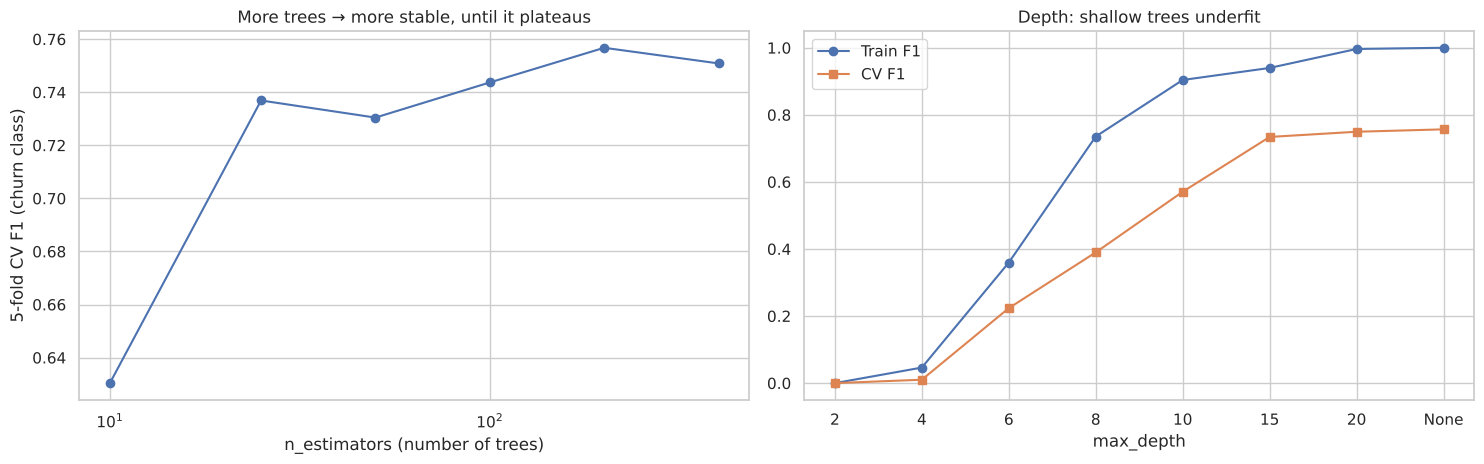

,param,value,cv_f1,train_f1
0,n_estimators,10,0.630,NaN
1,n_estimators,25,0.737,NaN
2,n_estimators,50,0.730,NaN
3,n_estimators,100,0.744,NaN
4,n_estimators,200,0.757,NaN
5,n_estimators,400,0.751,NaN
6,max_depth,2,0.000,0.000
7,max_depth,4,0.010,0.046
8,max_depth,6,0.224,0.360
9,max_depth,8,0.390,0.735


In [4]:
rows = []
for n in [10, 25, 50, 100, 200, 400]:
    r = cross_validate(RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring="f1")
    rows.append({"param": "n_estimators", "value": n, "cv_f1": r["test_score"].mean()})
for d in [2, 4, 6, 8, 10, 15, 20, None]:
    r = cross_validate(RandomForestClassifier(n_estimators=200, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
    rows.append({"param": "max_depth", "value": "None" if d is None else d,
                 "cv_f1": r["test_score"].mean(), "train_f1": r["train_score"].mean()})
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
s1 = sweep[sweep["param"] == "n_estimators"]
axes[0].plot(s1["value"].astype(int), s1["cv_f1"], "o-"); axes[0].set_xscale("log")
axes[0].set_xlabel("n_estimators (number of trees)"); axes[0].set_ylabel("5-fold CV F1 (churn class)")
axes[0].set_title("More trees → more stable, until it plateaus")
s2 = sweep[sweep["param"] == "max_depth"]
axes[1].plot(s2["value"].astype(str), s2["train_f1"], "o-", label="Train F1")
axes[1].plot(s2["value"].astype(str), s2["cv_f1"], "s-", label="CV F1")
axes[1].set_xlabel("max_depth"); axes[1].set_title("Depth: shallow trees underfit"); axes[1].legend()
plt.tight_layout(); plt.savefig(IMG / "hyperparameter_sweeps.png", dpi=120); plt.show()
sweep.round(3)

## 4. Hyperparameter tuning — randomized search with 5-fold CV
We optimise **F1 of the churn class** (balances precision and recall) rather than accuracy, because of the class imbalance.

In [5]:
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 8, 12, 16, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.3, 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "bootstrap": [True],
}
search = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), param_dist,
                            n_iter=40, scoring="f1", cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
t0 = time(); search.fit(X_train, y_train)
print(f"Search time: {time() - t0:.0f}s")
print("Best CV F1:", round(search.best_score_, 3))
print("Best params:", search.best_params_)

Search time: 143s
Best CV F1: 0.844
Best params: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 16, 'class_weight': 'balanced_subsample', 'bootstrap': True}


In [6]:
top = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").head(8)
top[["rank_test_score", "mean_test_score", "std_test_score", "params"]].round(3)

,rank_test_score,mean_test_score,std_test_score,params
31,1,0.844,0.014,"{'n_estimators': 300, 'min_samples_split': 10,..."
18,2,0.842,0.024,"{'n_estimators': 200, 'min_samples_split': 10,..."
9,3,0.840,0.022,"{'n_estimators': 200, 'min_samples_split': 10,..."
32,4,0.839,0.021,"{'n_estimators': 500, 'min_samples_split': 2, ..."
39,5,0.839,0.029,"{'n_estimators': 100, 'min_samples_split': 5, ..."
34,6,0.836,0.019,"{'n_estimators': 300, 'min_samples_split': 10,..."
11,7,0.836,0.020,"{'n_estimators': 500, 'min_samples_split': 5, ..."
7,8,0.836,0.014,"{'n_estimators': 200, 'min_samples_split': 2, ..."


In [7]:
best_rf = search.best_estimator_
pd.DataFrame([cv_summary(baseline, "RF default"), cv_summary(best_rf, "RF tuned")]).set_index("Model")

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
RF default,0.940 ± 0.006,0.979 ± 0.022,0.600 ± 0.040,0.744 ± 0.032,0.920 ± 0.019
RF tuned,0.957 ± 0.004,0.906 ± 0.042,0.791 ± 0.029,0.844 ± 0.014,0.915 ± 0.013


## 5. Final evaluation on the held-out test set

In [8]:
rows = []
for name, m in [("RF default", baseline.fit(X_train, y_train)), ("RF tuned", best_rf)]:
    p = m.predict(X_test); pr = m.predict_proba(X_test)[:, 1]
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, pr)})
test_results = pd.DataFrame(rows).set_index("Model").round(3)
test_results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
RF default,0.952,0.985,0.674,0.800,0.942
RF tuned,0.963,0.898,0.832,0.863,0.935


In [9]:
print(classification_report(y_test, best_rf.predict(X_test), target_names=["Stay", "Churn"], digits=3))

              precision    recall  f1-score   support

        Stay      0.972     0.984     0.978       572
       Churn      0.898     0.832     0.863        95

    accuracy                          0.963       667
   macro avg      0.935     0.908     0.921       667
weighted avg      0.962     0.963     0.962       667



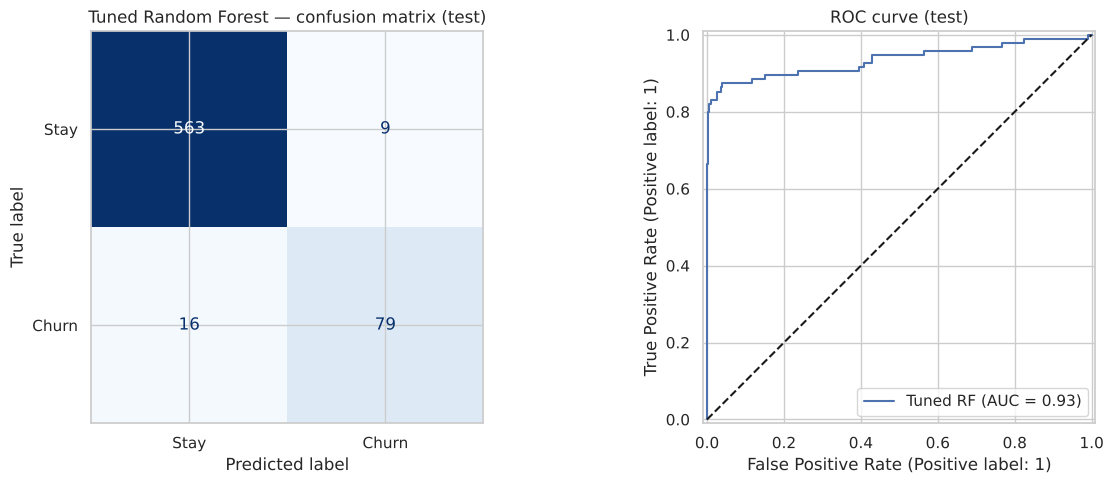

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_estimator(best_rf, X_test, y_test, display_labels=["Stay", "Churn"], cmap="Blues",
                                      colorbar=False, ax=axes[0])
axes[0].set_title("Tuned Random Forest — confusion matrix (test)")
RocCurveDisplay.from_estimator(best_rf, X_test, y_test, ax=axes[1], name="Tuned RF")
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curve (test)")
plt.tight_layout(); plt.savefig(IMG / "evaluation.png", dpi=120); plt.show()

## 6. Feature-importance analysis
* **Impurity-based (MDI)** importance — how much each feature reduces Gini impurity across all trees. Fast, but biased towards
  continuous/high-cardinality features.
* **Permutation importance** on the *test set* — how much the F1 score drops when a feature's values are shuffled. Slower but
  more reliable, and it measures importance on unseen data.

In [11]:
mdi = pd.Series(best_rf.feature_importances_, index=X_train.columns)
# group the 51 State dummies / 3 area-code dummies so they are comparable with single features
def group(s):
    s = s.copy()
    out = s[~s.index.str.startswith(("State_", "Area code_"))]
    out["State (51 dummies, total)"] = s[s.index.str.startswith("State_")].sum()
    out["Area code (3 dummies, total)"] = s[s.index.str.startswith("Area code_")].sum()
    return out.sort_values(ascending=False)
mdi_g = group(mdi)

perm = permutation_importance(best_rf, X_test, y_test, scoring="f1", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns)
perm_g = group(perm_s)

imp = pd.DataFrame({"MDI importance": mdi_g, "Permutation importance (Δ F1)": perm_g}).sort_values("MDI importance", ascending=False)
imp.round(4)

,MDI importance,Permutation importance (Δ F1)
Total day minutes,0.1858,0.3510
Customer service calls,0.1834,0.2093
Total minutes,0.1381,0.3540
International plan,0.1367,0.1279
Total intl minutes,0.0536,0.0506
"State (51 dummies, total)",0.0509,-0.0019
Total intl calls,0.0447,0.0426
Total eve minutes,0.0408,0.0277
Number vmail messages,0.0285,0.0587
Total night minutes,0.0273,-0.0003


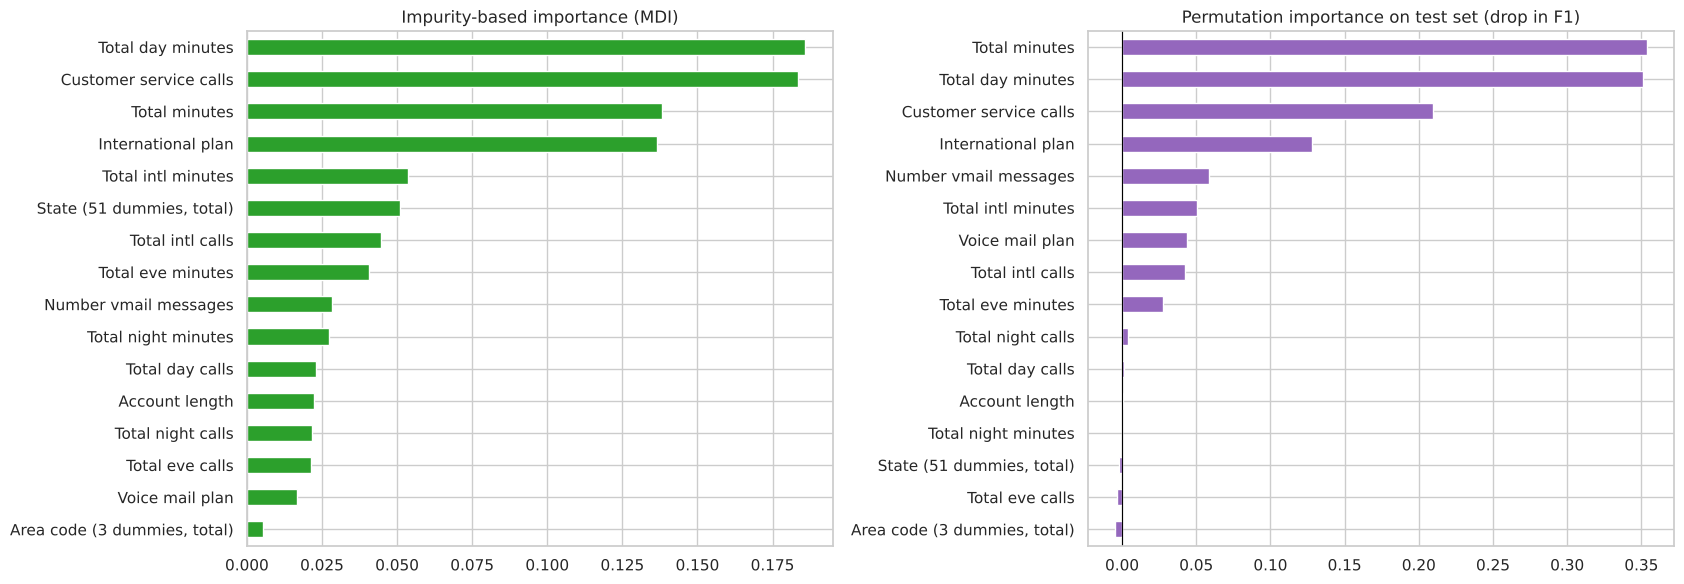

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
mdi_g.sort_values().plot(kind="barh", ax=axes[0], color="tab:green"); axes[0].set_title("Impurity-based importance (MDI)")
perm_g.sort_values().plot(kind="barh", ax=axes[1], color="tab:purple")
axes[1].set_title("Permutation importance on test set (drop in F1)"); axes[1].axvline(0, color="black", lw=.8)
plt.tight_layout(); plt.savefig(IMG / "feature_importance.png", dpi=120); plt.show()

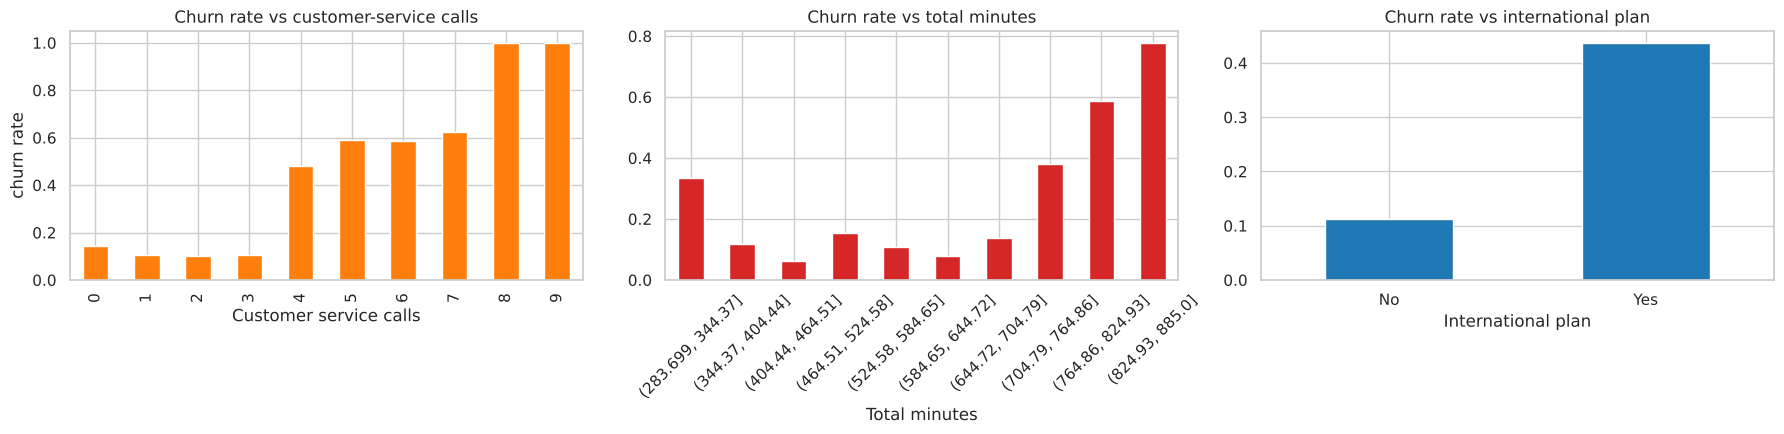

In [13]:
# How the top features relate to churn
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
tr.groupby("Customer service calls")["Churn"].mean().plot(kind="bar", ax=axes[0], color="tab:orange")
axes[0].set_title("Churn rate vs customer-service calls"); axes[0].set_ylabel("churn rate")
tr.groupby(pd.cut(tr["Total minutes"], 10))["Churn"].mean().plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set_title("Churn rate vs total minutes"); axes[1].tick_params(axis="x", rotation=45)
tr.groupby("International plan")["Churn"].mean().plot(kind="bar", ax=axes[2], color="tab:blue")
axes[2].set_title("Churn rate vs international plan"); axes[2].set_xticklabels(["No", "Yes"], rotation=0)
plt.tight_layout(); plt.savefig(IMG / "top_feature_effects.png", dpi=120); plt.show()

## Conclusions
**Tuning**
* More trees stabilise the model until ~200 trees, after which CV F1 plateaus (~0.75).
* Shallow trees badly **underfit** on this imbalanced problem (max_depth ≤ 6 → F1 < 0.25); depth 15–20+ is needed.
* The randomized search (40 settings × 5 folds) found: `n_estimators=300, max_depth=16, min_samples_split=10,
  min_samples_leaf=2, max_features=0.5, class_weight="balanced_subsample"`.
  Up-weighting churners and letting each split look at 50 % of the features were the key changes.

**Results**
| | CV F1 (5-fold) | Test precision | Test recall | Test F1 | Test accuracy |
|---|---|---|---|---|---|
| Default RF | 0.744 ± 0.032 | 0.985 | 0.674 | 0.800 | 0.952 |
| **Tuned RF** | **0.844 ± 0.014** | 0.898 | **0.832** | **0.863** | **0.963** |

The tuned forest catches **83 % of churners** (vs 67 %) while 9 out of 10 churn alerts are correct.
It is far stronger than the logistic regression from Level 2 (test F1 0.86 vs 0.49) because trees capture non-linear effects
such as the jump in churn after the 4th service call.

**Most important features** (both methods agree):
1. **Total day minutes / Total minutes** — heavy users (highest bills) churn the most.
2. **Customer service calls** — churn jumps from ~10 % to ~50 %+ at 4 or more calls.
3. **International plan** — plan holders churn far more often.
4. International minutes/calls and voice-mail messages play a smaller role.

`State`, `Area code`, `Account length` and the night/evening call counts have near-zero (or negative) permutation importance —
they add almost nothing on unseen data and could be dropped.